# Phase 11.3 - Meta-policy (Hybrid vs Behavior)

Este notebook ejecuta `run_phase11_3_meta_policy.py` y revisa métricas en validación/holdout, umbrales calibrados y curvas de equity.

In [1]:
from pathlib import Path
import json
import subprocess

ROOT = Path('.')
PHASE11 = ROOT / 'phases/phase11_offline_rl'
SCRIPT = PHASE11 / 'run_phase11_3_meta_policy.py'
OUT = PHASE11 / 'output_phase11_3_meta_policy_GBPUSD'

cmd = ['python', str(SCRIPT)]
res = subprocess.run(cmd, capture_output=True, text=True)
print(res.stdout)
if res.returncode != 0:
    print(res.stderr)
    raise RuntimeError(f'Error running {SCRIPT.name}')

Saved summary: ./phases/phase11_offline_rl/output_phase11_3_meta_policy_GBPUSD/GBPUSD_phase11_3_summary.json
Holdout metrics: {'behavior': {'acc_action_3': 0.32619577308120135, 'f1_macro_action_3': 0.32455052218516484, 'avg_net_return': 0.00016313956810976485, 'cum_net_return': 0.5866498869227144, 'std_net_return': 0.004038152876353244, 'trade_rate': 0.3604004383087158, 'sharpe_ann': 3.14182826856007, 'win_rate_trades': 0.5478395061728395}, 'cql': {'acc_action_3': 0.25528364849833146, 'f1_macro_action_3': 0.24013865365341813, 'avg_net_return': 0.00010810211957526335, 'cum_net_return': 0.388735221992647, 'std_net_return': 0.0030520281593698836, 'trade_rate': 0.2177419364452362, 'sharpe_ann': 2.754555734494888, 'win_rate_trades': 0.5555555555555556}, 'hybrid_advantage': {'acc_action_3': 0.34399332591768633, 'f1_macro_action_3': 0.34245903548058837, 'avg_net_return': 0.00015864660640717464, 'cum_net_return': 0.5704931966402, 'std_net_return': 0.004165753742265042, 'trade_rate': 0.40628474

In [2]:
import json
import pandas as pd

summary = json.loads((OUT / 'GBPUSD_phase11_3_summary.json').read_text())
compare = pd.read_csv(OUT / 'GBPUSD_phase11_3_policy_comparison.csv')

print('Best calibration:', summary['meta_calibration_best'])
compare

Best calibration: {'gate_thr': 0.45, 'inf_min': 0.3, 'q_conf_min': 0.3, 'score': -0.18825748021348598}


,split,policy,acc_action_3,f1_macro_action_3,avg_net_return,cum_net_return,std_net_return,trade_rate,sharpe_ann,win_rate_trades
0,validation,behavior,0.337427,0.332445,0.000228,0.390024,0.005181,0.361988,3.423678,0.531502
1,validation,cql,0.230409,0.196981,0.000303,0.518161,0.004434,0.118713,5.315055,0.591133
2,validation,hybrid_advantage,0.339766,0.335406,0.000266,0.455675,0.005351,0.370175,3.872922,0.532385
3,validation,meta_gate,0.339766,0.335417,0.000268,0.458706,0.005350,0.369591,3.899112,0.533228
4,holdout,behavior,0.326196,0.324551,0.000163,0.586650,0.004038,0.360400,3.141828,0.547840
5,holdout,cql,0.255284,0.240139,0.000108,0.388735,0.003052,0.217742,2.754556,0.555556
6,holdout,hybrid_advantage,0.343993,0.342459,0.000159,0.570493,0.004166,0.406285,2.961714,0.539357
7,holdout,meta_gate,0.343159,0.341499,0.000158,0.569898,0.004158,0.403782,2.964369,0.539945


In [3]:
grid = pd.read_csv(OUT / 'GBPUSD_phase11_3_meta_threshold_grid.csv')
grid.head(12)

,gate_thr,inf_min,q_conf_min,score,acc_action_3,f1_macro_action_3,avg_net_return,cum_net_return,std_net_return,trade_rate,sharpe_ann,win_rate_trades
0,0.45,0.3,0.3,-0.188257,0.385965,0.370981,-0.000016,-0.008,0.003753,0.37037,-0.32315,0.547368
1,0.45,0.3,0.4,-0.188257,0.385965,0.370981,-0.000016,-0.008,0.003753,0.37037,-0.32315,0.547368
2,0.45,0.3,0.5,-0.188257,0.385965,0.370981,-0.000016,-0.008,0.003753,0.37037,-0.32315,0.547368
3,0.45,0.3,0.6,-0.188257,0.385965,0.370981,-0.000016,-0.008,0.003753,0.37037,-0.32315,0.547368
4,0.45,0.3,0.7,-0.188257,0.385965,0.370981,-0.000016,-0.008,0.003753,0.37037,-0.32315,0.547368
5,0.45,0.4,0.3,-0.188257,0.385965,0.370981,-0.000016,-0.008,0.003753,0.37037,-0.32315,0.547368
6,0.45,0.4,0.4,-0.188257,0.385965,0.370981,-0.000016,-0.008,0.003753,0.37037,-0.32315,0.547368
7,0.45,0.4,0.5,-0.188257,0.385965,0.370981,-0.000016,-0.008,0.003753,0.37037,-0.32315,0.547368
8,0.45,0.4,0.6,-0.188257,0.385965,0.370981,-0.000016,-0.008,0.003753,0.37037,-0.32315,0.547368
9,0.45,0.4,0.7,-0.188257,0.385965,0.370981,-0.000016,-0.008,0.003753,0.37037,-0.32315,0.547368


In [4]:
coef = pd.read_csv(OUT / 'GBPUSD_phase11_3_meta_coefficients.csv')
coef.head(15)

,feature,coef,abs_coef
0,hybrid_minus_behavior,-2.573220,2.573220
1,changed,2.565564,2.565564
2,hybrid_action,-1.700640,1.700640
3,behavior_nonflat,-1.326117,1.326117
4,hybrid_nonflat,1.239448,1.239448
5,behavior_action,0.872580,0.872580
6,q_margin,-0.835354,0.835354
7,pred_progress,0.591776,0.591776
8,q_conf,-0.423427,0.423427
9,q_adv,0.346885,0.346885


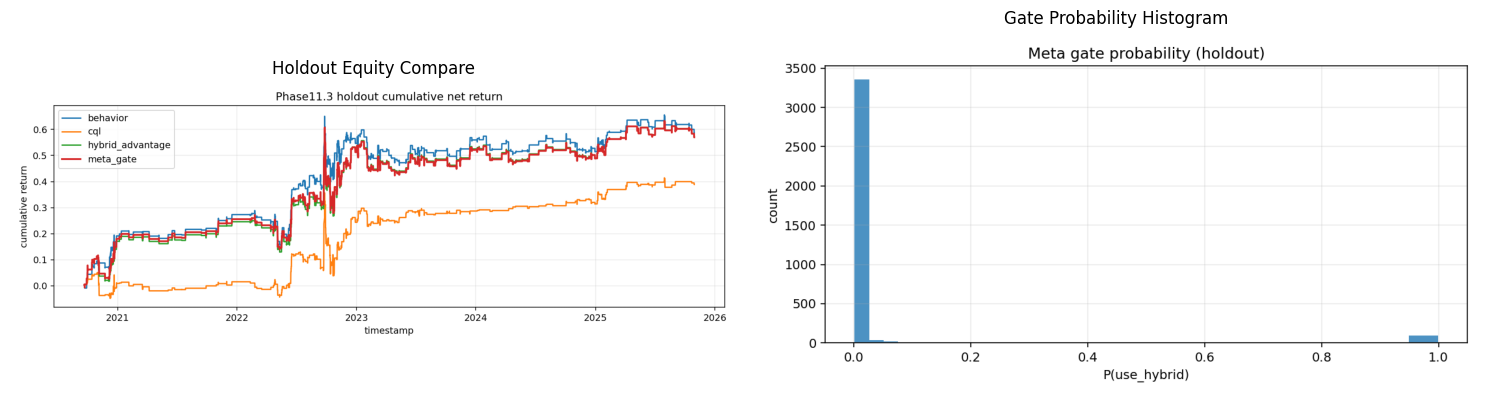

In [5]:
import matplotlib.pyplot as plt

img1 = plt.imread(OUT / 'GBPUSD_phase11_3_holdout_equity_compare.png')
img2 = plt.imread(OUT / 'GBPUSD_phase11_3_gate_probability_hist.png')

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
ax[0].imshow(img1)
ax[0].axis('off')
ax[0].set_title('Holdout Equity Compare')

ax[1].imshow(img2)
ax[1].axis('off')
ax[1].set_title('Gate Probability Histogram')

plt.tight_layout()
plt.show()